# Olist Data Platform — T5 Gold Dashboard

**Sumber:** PostgreSQL `mart.*` dan query bersama
`olist/mart_queries.py`.

**Q1:** Pendapatan produk pada order delivered.
**Q2:** Hubungan keterlambatan dengan skor review.
**Q3:** Performa seller dengan minimal 30 order evaluable.
**Q4:** Segmentasi pelanggan berdasarkan RFM.
**Streaming:** Freshness event valid unik yang tersimpan.

Analisis bulanan Q1 dan Q2 menggunakan bulan lengkap:
**Januari 2017 sampai Agustus 2018**.

Semua insight di bawah dihitung saat notebook dijalankan.


In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psycopg
from dotenv import load_dotenv

ROOT = Path.cwd().resolve()
if not (ROOT / "olist" / "mart_queries.py").exists():
    ROOT = ROOT.parent

if not (ROOT / "olist" / "mart_queries.py").exists():
    raise FileNotFoundError(
        "Jalankan notebook dari root starter atau folder notebooks."
    )

sys.path.insert(0, str(ROOT))
load_dotenv(ROOT / ".env")

from olist.mart_queries import QUERIES

def query_df(sql):
    with psycopg.connect(
        host=os.getenv("POSTGRES_HOST", "localhost"),
        port=int(os.getenv("POSTGRES_PORT", "5432")),
        dbname=os.environ["POSTGRES_DB"],
        user=os.environ["POSTGRES_USER"],
        password=os.environ["POSTGRES_PASSWORD"],
    ) as conn:
        with conn.cursor() as cur:
            cur.execute(sql)
            columns = [col.name for col in cur.description]
            rows = cur.fetchall()
    return pd.DataFrame(rows, columns=columns)

def numeric(df, *cols):
    for col in cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True

print("PostgreSQL connection and shared queries: READY")


Matplotlib is building the font cache; this may take a moment.


PostgreSQL connection and shared queries: READY


## Q1 — Tren pendapatan bulanan

Definisi revenue: jumlah `price` produk pada order
`delivered`, tanpa ongkos kirim.

Sumber: `mart.monthly_sales`. Grafik hanya menggunakan
bulan yang ditandai lengkap.


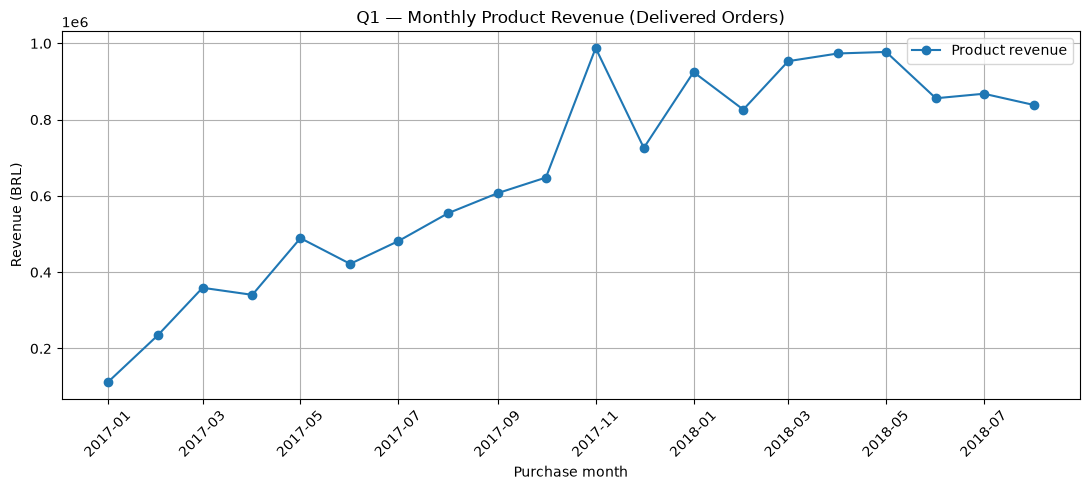

INSIGHT Q1: Revenue produk tertinggi terjadi pada November 2017, yaitu BRL 987,765.37. Periode mencakup 20 bulan lengkap.


In [2]:
q1 = query_df(QUERIES["q1_monthly_revenue"])
q1 = numeric(q1, "product_revenue_brl", "freight_brl")
q1["month_start"] = pd.to_datetime(q1["month_start"])

fig, ax = plt.subplots()
ax.plot(q1["month_start"], q1["product_revenue_brl"],
        marker="o", label="Product revenue")
ax.set_title("Q1 — Monthly Product Revenue (Delivered Orders)")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Revenue (BRL)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

peak = q1.loc[q1["product_revenue_brl"].idxmax()]
print(
    f"INSIGHT Q1: Revenue produk tertinggi terjadi pada "
    f"{peak['month_start']:%B %Y}, yaitu "
    f"BRL {peak['product_revenue_brl']:,.2f}. "
    f"Periode mencakup {len(q1)} bulan lengkap."
)


## Q2 — Review dan keterlambatan pengiriman

`LATE` dan `ON_TIME` hanya mencakup order yang
`is_late IS NOT NULL` dan memiliki review terpilih.

Skor review memiliki skala 1–5.


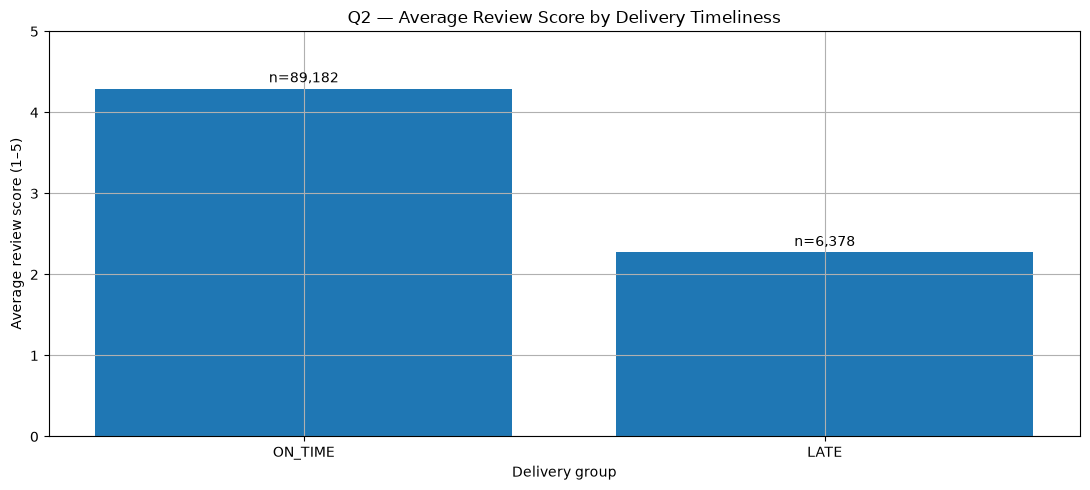

INSIGHT Q2: Rata-rata review tepat waktu 4.291/5 (n=89,182), dibanding 2.271/5 (n=6,378) untuk terlambat. Selisihnya 2.020 poin.


In [3]:
q2 = query_df(QUERIES["q2_review_vs_lateness"])
q2 = numeric(q2, "reviewed_orders", "avg_review_score")
q2 = q2.set_index("delivery_group").loc[
    ["ON_TIME", "LATE"]
].reset_index()

fig, ax = plt.subplots()
bars = ax.bar(q2["delivery_group"], q2["avg_review_score"])
ax.set_title("Q2 — Average Review Score by Delivery Timeliness")
ax.set_xlabel("Delivery group")
ax.set_ylabel("Average review score (1–5)")
ax.set_ylim(0, 5)
for bar, n in zip(bars, q2["reviewed_orders"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"n={int(n):,}",
        ha="center"
    )
plt.tight_layout()
plt.show()

on_time = q2.set_index("delivery_group").loc["ON_TIME"]
late = q2.set_index("delivery_group").loc["LATE"]
print(
    f"INSIGHT Q2: Rata-rata review tepat waktu "
    f"{on_time['avg_review_score']:.3f}/5 "
    f"(n={int(on_time['reviewed_orders']):,}), "
    f"dibanding {late['avg_review_score']:.3f}/5 "
    f"(n={int(late['reviewed_orders']):,}) untuk terlambat. "
    f"Selisihnya "
    f"{on_time['avg_review_score'] - late['avg_review_score']:.3f} poin."
)


## Q3 — Seller scorecard

Menampilkan sepuluh seller eligible dengan revenue produk
delivered tertinggi.

Syarat kelayakan perbandingan late rate:
**minimal 30 order evaluable per seller**.


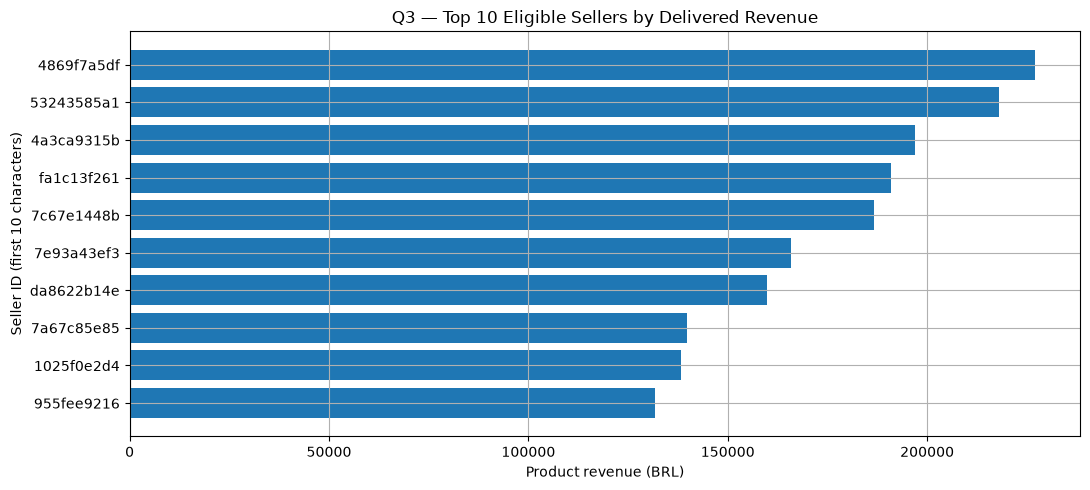

INSIGHT Q3: Seller 4869f7a5dfa277a7dca6462dcf3b52b2 menghasilkan BRL 226,987.93, dengan 1,124 order evaluable dan late rate 10.50%.


In [4]:
q3 = query_df(QUERIES["q3_top_sellers"])
q3 = numeric(
    q3, "delivered_product_revenue_brl",
    "evaluable_orders", "late_rate_pct"
)
q3["short_id"] = q3["seller_id"].str[:10]

fig, ax = plt.subplots()
ax.barh(
    q3["short_id"].iloc[::-1],
    q3["delivered_product_revenue_brl"].iloc[::-1]
)
ax.set_title("Q3 — Top 10 Eligible Sellers by Delivered Revenue")
ax.set_xlabel("Product revenue (BRL)")
ax.set_ylabel("Seller ID (first 10 characters)")
plt.tight_layout()
plt.show()

top = q3.iloc[0]
print(
    f"INSIGHT Q3: Seller {top['seller_id']} menghasilkan "
    f"BRL {top['delivered_product_revenue_brl']:,.2f}, "
    f"dengan {int(top['evaluable_orders']):,} order evaluable "
    f"dan late rate {top['late_rate_pct']:.2f}%."
)


## Q4 — Segmentasi pelanggan RFM

Recency dihitung dari tanggal pembelian delivered terakhir
dalam dataset + 1 hari, bukan tanggal saat dashboard dibuka.

Frequency menggunakan ambang diskret, bukan kuintil mentah.


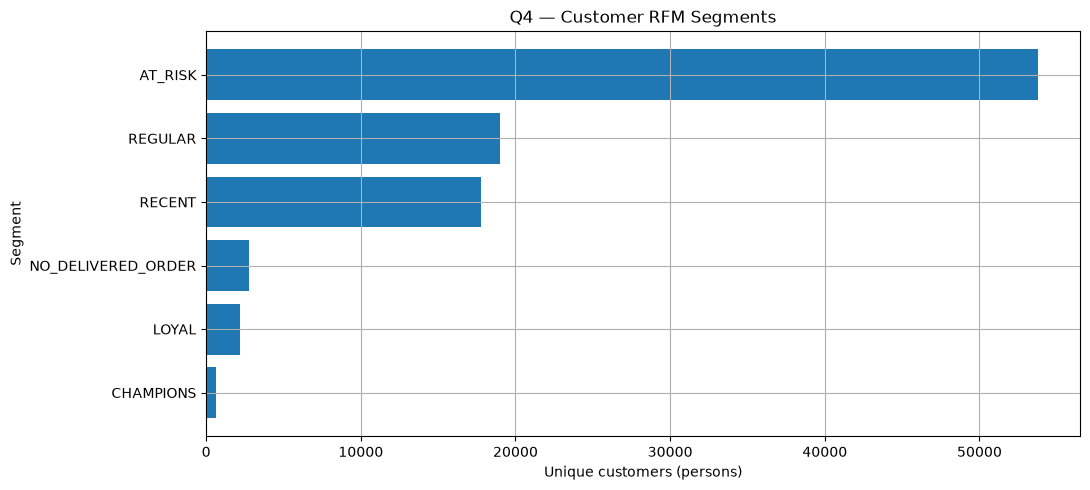

INSIGHT Q4: Segmen terbesar adalah AT_RISK dengan 53,810 customer unik dari 96,096 customer.


In [5]:
q4 = query_df(QUERIES["q4_rfm_segments"])
q4 = numeric(
    q4, "customers", "delivered_orders", "monetary_brl"
)
q4 = q4.sort_values("customers")

fig, ax = plt.subplots()
ax.barh(q4["segment"], q4["customers"])
ax.set_title("Q4 — Customer RFM Segments")
ax.set_xlabel("Unique customers (persons)")
ax.set_ylabel("Segment")
plt.tight_layout()
plt.show()

largest = q4.loc[q4["customers"].idxmax()]
print(
    f"INSIGHT Q4: Segmen terbesar adalah "
    f"{largest['segment']} dengan "
    f"{int(largest['customers']):,} customer unik "
    f"dari {int(q4['customers'].sum()):,} customer."
)


## Streaming — Freshness

Grafik menampilkan p95 freshness dalam detik,
berdasarkan menit konsumsi event.

Sumber: `mart.stream_freshness`, yang dibangun dari
`stream.order_events`.

Karena tabel sumber menyimpan event valid unik,
grafik ini **bukan** ukuran seluruh pesan Kafka termasuk DLQ
dan duplikat. Menit yang tidak memiliki event tidak ditampilkan.


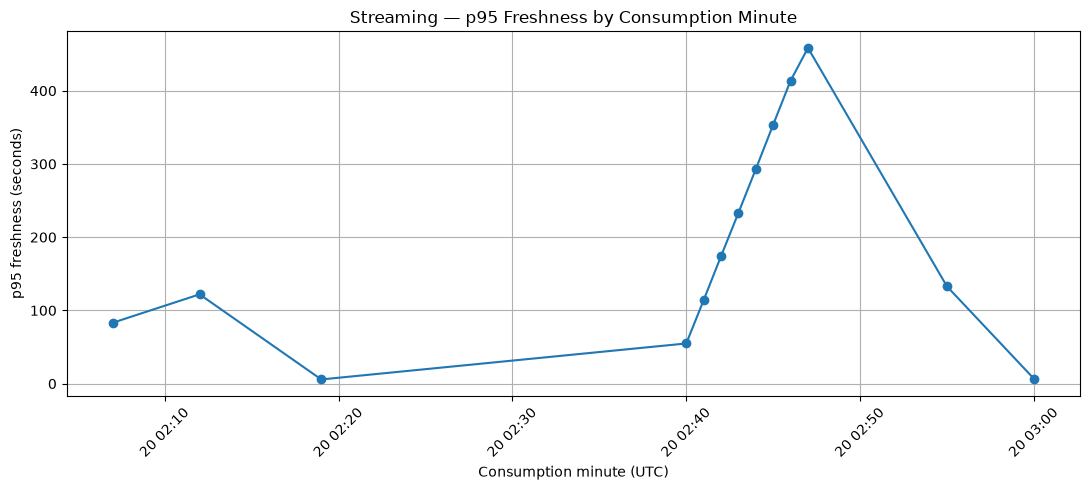

INSIGHT STREAM: p95 freshness per menit tertinggi adalah 458.45 detik pada 2026-10-20 02:47:00+00:00, dengan 47,471 event valid unik pada menit tersebut. Total observasi 13 menit.


In [6]:
fresh = query_df('''
    SELECT
        consumed_minute,
        valid_unique_events,
        p50_freshness_ms,
        p95_freshness_ms
    FROM mart.stream_freshness
    ORDER BY consumed_minute
''')
fresh = numeric(
    fresh,
    "valid_unique_events",
    "p50_freshness_ms",
    "p95_freshness_ms"
)
fresh["consumed_minute"] = pd.to_datetime(
    fresh["consumed_minute"], utc=True
)
fresh["p95_seconds"] = fresh["p95_freshness_ms"] / 1000

fig, ax = plt.subplots()
ax.plot(
    fresh["consumed_minute"],
    fresh["p95_seconds"],
    marker="o"
)
ax.set_title("Streaming — p95 Freshness by Consumption Minute")
ax.set_xlabel("Consumption minute (UTC)")
ax.set_ylabel("p95 freshness (seconds)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

worst = fresh.loc[fresh["p95_seconds"].idxmax()]
print(
    f"INSIGHT STREAM: p95 freshness per menit tertinggi "
    f"adalah {worst['p95_seconds']:,.2f} detik "
    f"pada {worst['consumed_minute']}, "
    f"dengan {int(worst['valid_unique_events']):,} "
    f"event valid unik pada menit tersebut. "
    f"Total observasi {len(fresh)} menit."
)


## Rekonsiliasi pembayaran — Pemeriksaan tambahan

Toleransi kecocokan adalah **BRL 0,01**.
Kategori investigasi tidak otomatis membuktikan
bahwa selisih akuntansi sudah terjelaskan.


In [7]:
recon = query_df(QUERIES["reconciliation_match_rate"])
recon = numeric(
    recon,
    "total_orders",
    "matched_orders",
    "match_rate_pct",
    "unmatched_absolute_difference_brl",
    "unexplained_absolute_difference_brl"
)
display(recon)

r = recon.iloc[0]
print(
    f"REKONSILIASI: {int(r['matched_orders']):,} "
    f"dari {int(r['total_orders']):,} order cocok "
    f"({r['match_rate_pct']:.3f}%). "
    f"Total selisih absolut pada order tidak cocok "
    f"BRL {r['unmatched_absolute_difference_brl']:,.2f}; "
    f"kelas UNEXPLAINED BRL "
    f"{r['unexplained_absolute_difference_brl']:,.2f}."
)


,total_orders,matched_orders,match_rate_pct,unmatched_absolute_difference_brl,unexplained_absolute_difference_brl
0,99441,98362,98.915,166004.63,78.87


REKONSILIASI: 98,362 dari 99,441 order cocok (98.915%). Total selisih absolut pada order tidak cocok BRL 166,004.63; kelas UNEXPLAINED BRL 78.87.
